In [1]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

In [4]:
import math
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow. keras. layers import Dense
from tensorflow. keras. layers import LSTM
from tensorflow. keras. layers import Dropout
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split

In [6]:
import pandas as pd

df = pd.read_csv(
    r"C:\Users\HP\Downloads\archive\Tesla.csv - Tesla.csv.csv",
    parse_dates=True,
    index_col="Date"
)

df.head()

,Open,High,Low,Close,Volume,Adj Close
Date,,,,,,
2010-06-29,19.000000,25.00,17.540001,23.889999,18766300,23.889999
2010-06-30,25.790001,30.42,23.299999,23.830000,17187100,23.830000
2010-07-01,25.000000,25.92,20.270000,21.959999,8218800,21.959999
2010-07-02,23.000000,23.10,18.709999,19.200001,5139800,19.200001
2010-07-06,20.000000,20.00,15.830000,16.110001,6866900,16.110001


In [5]:
!pip install seaborn

In [7]:
df.shape

(1692, 6)

In [8]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 1692 entries, 2010-06-29 to 2017-03-17
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Open       1692 non-null   float64
 1   High       1692 non-null   float64
 2   Low        1692 non-null   float64
 3   Close      1692 non-null   float64
 4   Volume     1692 non-null   int64  
 5   Adj Close  1692 non-null   float64
dtypes: float64(5), int64(1)
memory usage: 92.5 KB


In [9]:
df.describe()

,Open,High,Low,Close,Volume,Adj Close
count,1692.000000,1692.000000,1692.000000,1692.000000,1.692000e+03,1692.000000
mean,132.441572,134.769698,129.996223,132.428658,4.270741e+06,132.428658
std,94.309923,95.694914,92.855227,94.313187,4.295971e+06,94.313187
min,16.139999,16.629999,14.980000,15.800000,1.185000e+05,15.800000
25%,30.000000,30.650000,29.215000,29.884999,1.194350e+06,29.884999
50%,156.334999,162.370002,153.150002,158.160004,3.180700e+06,158.160004
75%,220.557495,224.099999,217.119999,220.022503,5.662100e+06,220.022503
max,287.670013,291.420013,280.399994,286.040009,3.716390e+07,286.040009


In [10]:
df.isnull().sum()

Open         0
High         0
Low          0
Close        0
Volume       0
Adj Close    0
dtype: int64

In [11]:
df = df.dropna()

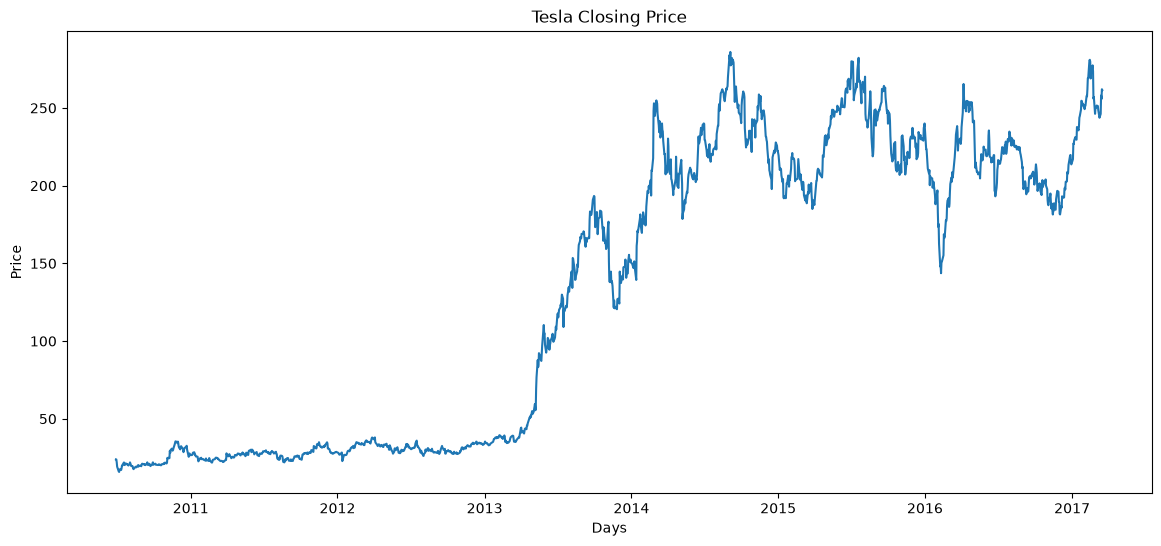

In [12]:
plt.figure(figsize=(14,6))

plt.plot(df["Close"])

plt.title("Tesla Closing Price")

plt.xlabel("Days")

plt.ylabel("Price")

plt.show()

In [13]:
data = df[['Close']]

In [14]:
scaler = MinMaxScaler(feature_range=(0,1))

scaled_data = scaler.fit_transform(data)

In [15]:
X = []
y = []

for i in range(60, len(scaled_data)):
    X.append(scaled_data[i-60:i,0])
    y.append(scaled_data[i,0])

X = np.array(X)
y = np.array(y)

In [16]:
print(X.shape)
print(y.shape)

(1632, 60)
(1632,)


In [17]:
X = np.reshape(X,(X.shape[0],X.shape[1],1))

In [18]:
print(X.shape)

(1632, 60, 1)


In [19]:
train_size = int(len(X) * 0.8)

X_train = X[:train_size]
X_test = X[train_size:]

y_train = y[:train_size]
y_test = y[train_size:]

print("Training samples:", X_train.shape)
print("Testing samples :", X_test.shape)

Training samples: (1305, 60, 1)
Testing samples : (327, 60, 1)


In [21]:
model = Sequential()

model.add(LSTM(units=50, return_sequences=True,
               input_shape=(X_train.shape[1], 1)))
model.add(Dropout(0.2))

model.add(LSTM(units=50))
model.add(Dropout(0.2))

model.add(Dense(25))
model.add(Dense(1))

C:\Users\HP\anaconda3\envs\guvi_lstm\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [22]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                     ┃ Output Shape            ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                      │ (None, 60, 50)          │        10,400 │
├──────────────────────────────────┼─────────────────────────┼───────────────┤
│ dropout (Dropout)                │ (None, 60, 50)          │             0 │
├──────────────────────────────────┼─────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                    │ (None, 50)              │        20,200 │
├──────────────────────────────────┼─────────────────────────┼───────────────┤
│ dropout_1 (Dropout)              │ (None, 50)              │             0 │
├──────────────────────────────────┼─────────────────────────┼───────────────┤
│ dense (Dense)                    │ (None, 25)              │         1,275 │
├──────────────────────────────────┼─────────────────────────┼───────────────┤
│ dense_1 (Dense)                  │ (None, 1)               │            26 │
└──────────────────────────────────┴─────────────────────────┴───────────────┘

 Total params: 31,901 (124.61 KB)

 Trainable params: 31,901 (124.61 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
model.compile(
    optimizer='adam',
    loss='mean_squared_error'
)

In [24]:
history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_test, y_test),
    verbose=1
)

Epoch 1/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 16s 129ms/step - loss: 0.0297 - val_loss: 0.0041
Epoch 2/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 4s 95ms/step - loss: 0.0044 - val_loss: 0.0023
Epoch 3/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 4s 87ms/step - loss: 0.0040 - val_loss: 0.0024
Epoch 4/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 4s 100ms/step - loss: 0.0034 - val_loss: 0.0038
Epoch 5/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 4s 94ms/step - loss: 0.0031 - val_loss: 0.0031
Epoch 6/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 4s 104ms/step - loss: 0.0028 - val_loss: 0.0020
Epoch 7/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 4s 95ms/step - loss: 0.0026 - val_loss: 0.0019
Epoch 8/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 4s 83ms/step - loss: 0.0023 - val_loss: 0.0026
Epoch 9/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 4s 87ms/step - loss: 0.0029 - val_loss: 0.0029
Epoch 10/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 4s 98ms/step - loss: 0.0021 - val_loss: 0.0019
Epoch 11/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 4s 99ms/step - loss: 0.0021 - val_loss: 0.0022
Epoch 12/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 4s 99ms/step - loss:

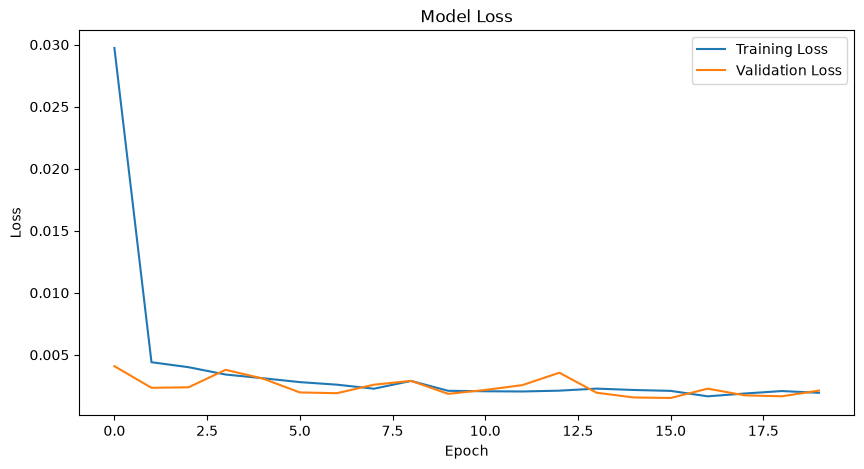

In [25]:
plt.figure(figsize=(10,5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

In [26]:
predictions = model.predict(X_test)

11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 147ms/step


In [27]:
predictions = scaler.inverse_transform(predictions)

y_test_actual = scaler.inverse_transform(
    y_test.reshape(-1,1)
)

In [28]:
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
import numpy as np

mse = mean_squared_error(y_test_actual, predictions)

rmse = np.sqrt(mse)

mae = mean_absolute_error(y_test_actual, predictions)

print("Mean Absolute Error :", mae)
print("Mean Squared Error  :", mse)
print("Root Mean Squared Error :", rmse)

Mean Absolute Error : 10.263536172110928
Mean Squared Error  : 154.66317120328767
Root Mean Squared Error : 12.436364870945516


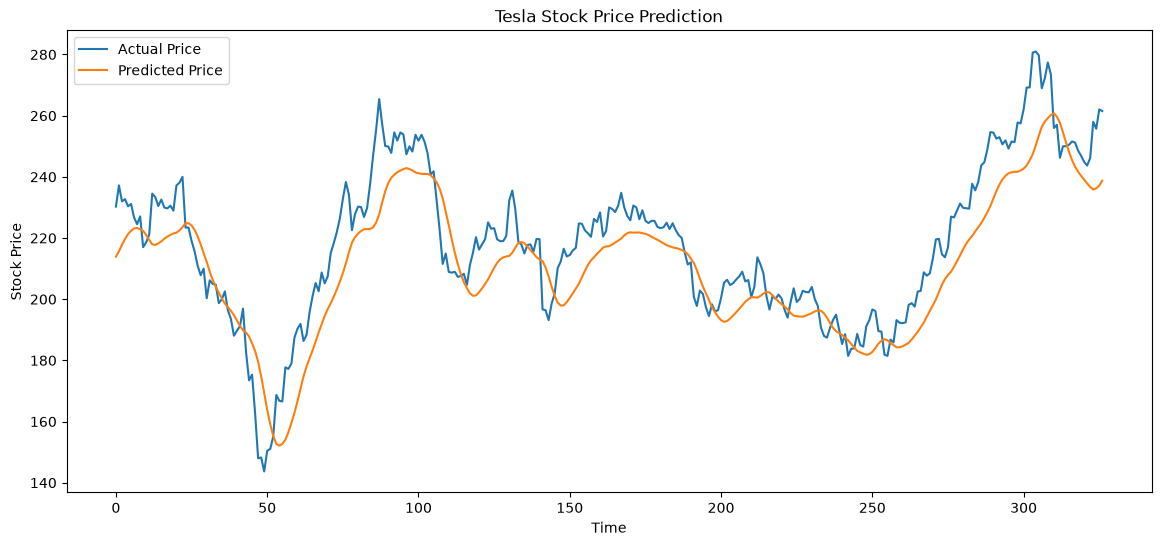

In [29]:
plt.figure(figsize=(14,6))

plt.plot(y_test_actual, label='Actual Price')

plt.plot(predictions, label='Predicted Price')

plt.title("Tesla Stock Price Prediction")

plt.xlabel("Time")

plt.ylabel("Stock Price")

plt.legend()

plt.show()

In [30]:
model.save("lstm_stock_prediction.keras")

In [31]:
results = pd.DataFrame({
    "Actual Price": y_test_actual.flatten(),
    "Predicted Price": predictions.flatten()
})

results.head(10)

,Actual Price,Predicted Price
0,230.259995,213.921921
1,237.190002,215.629532
2,231.990005,217.813629
3,232.710007,219.689590
4,230.380005,221.282837
5,231.130005,222.382477
6,226.720001,223.145645
7,224.520004,223.287613
8,227.070007,222.867493
9,217.020004,222.335037


In [ ]:
## Conclusion

This project implemented an LSTM-based deep learning model to forecast Tesla stock closing prices.

The dataset was preprocessed by handling missing values, selecting the closing price feature, scaling the data using MinMaxScaler, and creating 60-day sequences.

The LSTM model successfully learned temporal patterns in the stock prices and produced predictions that closely followed the actual values.

Model performance was evaluated using MAE, MSE, and RMSE. The prediction graph demonstrated that the model captured the overall trend, although some deviations occurred during periods of high volatility.

Future improvements may include:
- Using additional stock features (Open, High, Low, Volume)
- Hyperparameter tuning
- Bidirectional LSTM or GRU
- Attention mechanisms
- Incorporating news sentiment or technical indicators